In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!pip install lmfit
from lmfit import Model
from google.colab import drive
from scipy.optimize import curve_fit
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.7/97.7 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.2 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
df_dados

NameError: name 'df_dados' is not defined

corrente: [ 2.71  5.28  7.96 10.58 13.24 15.81 18.18 20.95 23.6  26.23 28.75] inc corrente: [0.00288675 0.00288675 0.00288675 0.00288675 0.00288675 0.00288675
 0.00288675 0.00288675 0.00288675 0.00288675 0.00288675] tensão: [ 1  2  3  4  5  6  7  8  9 10 11] inc tensão: [0.02886751 0.02886751 0.02886751 0.02886751 0.02886751 0.02886751
 0.02886751 0.02886751 0.02886751 0.02886751 0.02886751]
[[Model]]
    Model(lei_ohm)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7
    # data points      = 11
    # variables        = 2
    chi-square         = 9.47110232
    reduced chi-square = 1.05234470
    Akaike info crit   = 2.35385032
    Bayesian info crit = 3.14964086
    R-squared          = 0.99992825
[[Variables]]
    R:   0.38378265 +/- 0.00108366 (0.28%) (init = 1)
    V0: -0.04597231 +/- 0.01926557 (41.91%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(R, V0) = -0.8861


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/F 740/Termoionico/AjusteLinerResistencia.svg'

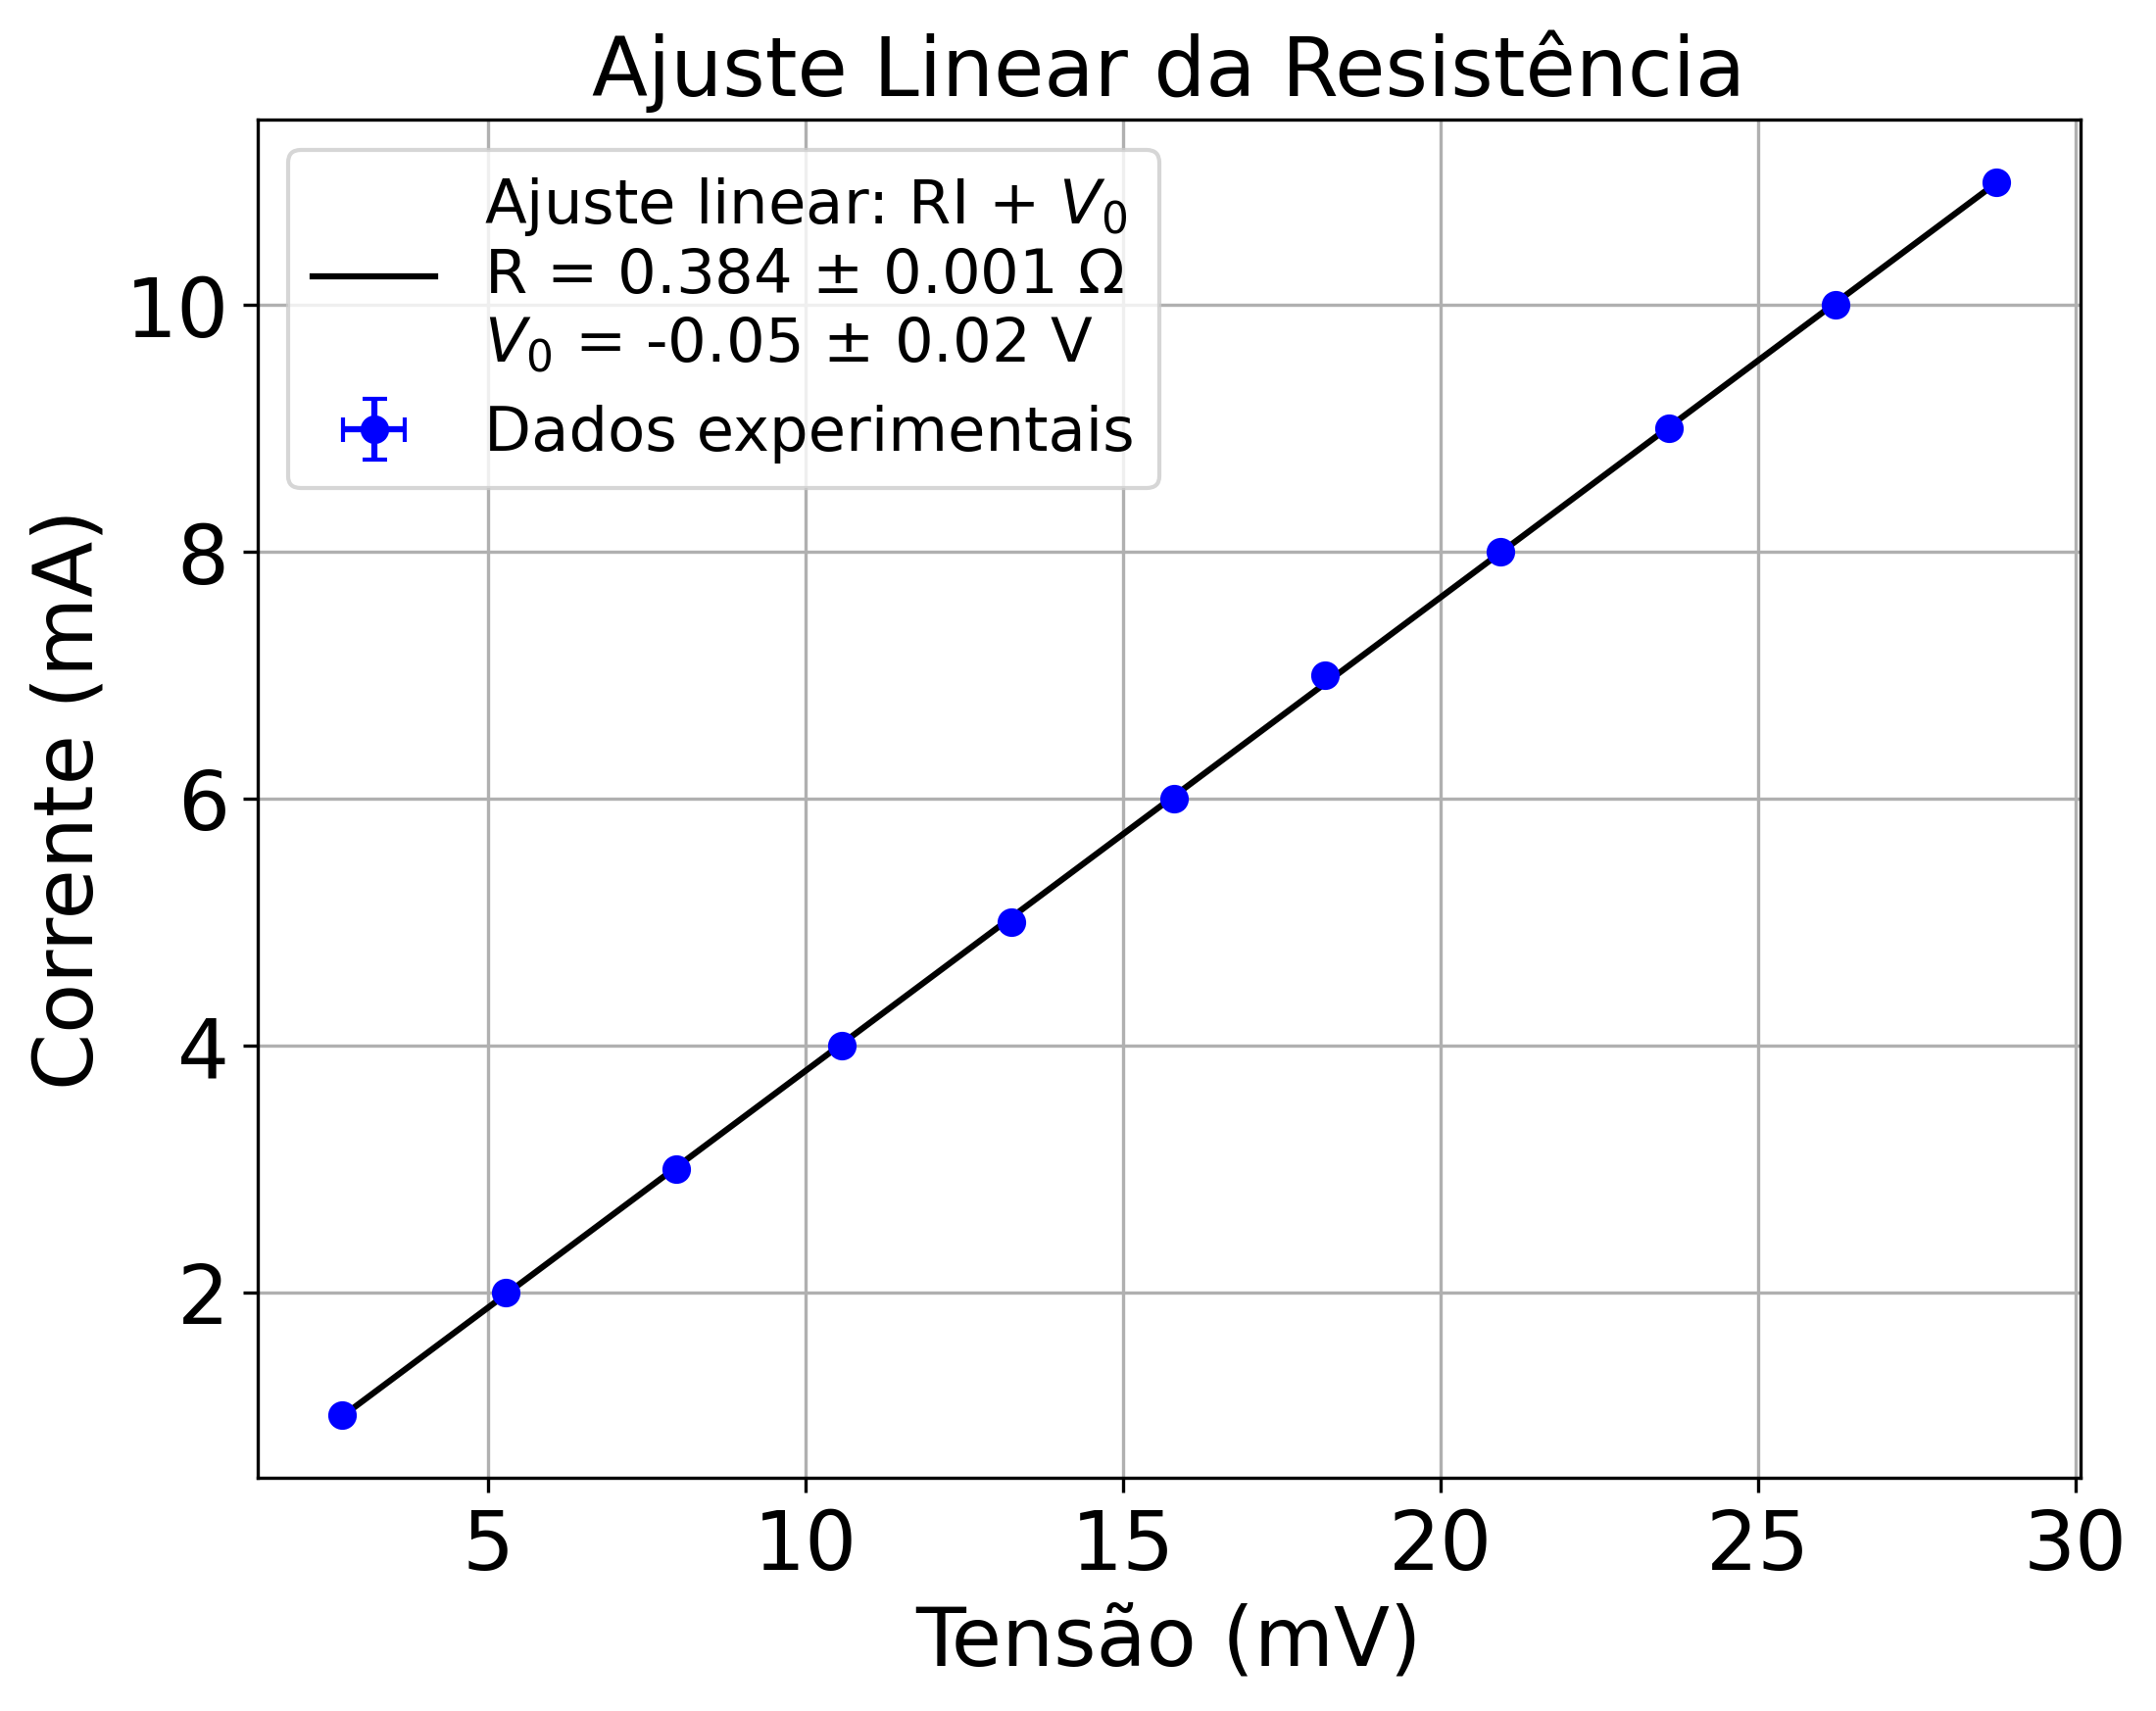

In [ ]:

df = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Termoionico/CalculoResistencia.csv")

I  = df["Corrente"].values
dI = df["Incerteza Corrente"].values
V  = df["Tensão"].values
dV = df["Incerteza Tensão"].values
print(f'corrente: {I} inc corrente: {dI} tensão: {V} inc tensão: {dV}')
# Modelo
def lei_ohm(I, R, V0):
    return R * I + V0


modelo = Model(lei_ohm)
resultado = modelo.fit(V, I=I, R=1, V0=0, weights=1/dV)
print(resultado.fit_report())

R_ajustado = resultado.params['R'].value
inc_R = resultado.params['R'].stderr
V0_ajustado = resultado.params['V0'].value
inc_V0 = resultado.params['V0'].stderr

I_fit = np.linspace(min(I), max(I), 100)
V_fit = resultado.eval(I=I_fit)

plt.figure(figsize=(8, 6), dpi=300)
plt.errorbar(I, V, xerr=dV, yerr=dI, fmt='o', label='Dados experimentais', capsize=3, color='blue')
plt.plot(I_fit, V_fit, 'k-',
         label=rf'Ajuste linear: RI + $V_0$' + '\n' +
                rf'R = {R_ajustado:.3f} $\pm$ {inc_R:.3f} $\Omega$' + '\n' +
                rf'$V_0$ = {V0_ajustado:.2f} $\pm$ {inc_V0:.2f} V')
plt.title('Ajuste Linear da Resistência', fontsize=20)
plt.xlabel('Tensão (mV)', fontsize=20)
plt.ylabel('Corrente (mA)', fontsize=20)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=15)
plt.grid(True)
plt.savefig('/content/drive/MyDrive/F 740/Termoionico/AjusteLinerResistencia.svg')
plt.savefig('/content/drive/MyDrive/F 740/Termoionico/AjusteLinerResistencia.png')
plt.show()

In [ ]:

# Dados
rho = 5.6e-8           # Resistividade do tungstênio (ohm·m)
L = 93e-3               # Comprimento em metros
d = 0.1778e-3           # Diâmetro em metros
dL = 1e-3               # Incerteza no comprimento
dd = 0.0001e-3          # (por exemplo) incerteza no diâmetro estimada

# Cálculo da resistência
A = np.pi * (d / 2)**2
R = rho * L / A

# Propagação da incerteza
rel_uncertainty = np.sqrt((dL / L)**2 + (2 * dd / d)**2)
dR = R * rel_uncertainty

incerteza_rr = (dR**2+0.001**2)**(1/2)

print(f"R = {round(R,3)} ± {round(dR,3)} Ω")
print(f"R - r = {round(0.384 - R,3)} ± {round(incerteza_rr,3)} Ω")


In [ ]:


# --- Dados experimentais ---
V = np.array([7.05, 7.99, 8.57, 9.07, 9.51, 10.01])  # tensão (V)
I = np.array([2.676, 2.878, 3.001, 3.104, 3.182, 3.286])  # corrente (A)

# Incertezas estimadas (ajuste conforme o instrumento)
dV = 0.028868  # V
dI = 0.002887  # A

# Constantes fornecidas
R0 = 0.210      # ohms
R0_err = 0.002  # ohms

Rr = 0.174      # ohms (resistor de correção)
Rr_err = 0.002  # ohms

# --- Funções físicas ---
def tr(x):
    """Temperatura em Kelvin em função de x = R/R0."""
    return 112 + 202*x - 1.81*x**2

def dtr_dx(x):
    """Derivada dT/dx para propagação de erro."""
    return 202 - 3.62*x

def tr_celsius(x):
    """Converte de Kelvin para Celsius."""
    return tr(x) - 273.15

def R(V, I):
    """Resistência corrigida (ohms)."""
    return V/I - Rr

def dR(V, I, dV, dI, dRr):
    """Incerteza em R pela propagação."""
    return np.sqrt((dV/I)**2 + ((V * dI) / I**2)**2 + dRr**2)

def R_R0(R, dR, R0, dR0):
    """Calcula R/R0 e sua incerteza."""
    raz = R / R0
    draz = raz * np.sqrt((dR/R)**2 + (dR0/R0)**2)
    return raz, draz

def dT(raz, draz):
    """Incerteza na temperatura propagada de Δ(R/R0)."""
    return np.abs(dtr_dx(raz)) * draz

# --- Cálculos ---
R_val = R(V, I)
dR_val = dR(V, I, dV, dI, Rr_err)
raz, draz = R_R0(R_val, dR_val, R0, R0_err)
T_K = tr(raz)
dT_K = dT(raz, draz)
T_C = tr_celsius(raz)
dT_C = dT_K  # mesma incerteza em °C (offset constante)

# --- Monta tabela de resultados ---
tabela_temp = pd.DataFrame({
    "V (V)": V,
    "I (A)": I,
    "R (Ω)": np.round(R_val, 2),
    "ΔR (Ω)": np.round(dR_val, 2),
    "R/R₀": np.round(raz, 1),
    "Δ(R/R₀)": np.round(draz, 1),
    "T (K)": np.round(T_K, 0),
    "ΔT (K)": np.round(dT_K, 0),
    "T (°C)": np.round(T_C, 0),
    "ΔT (°C)": np.round(dT_C, 0)
})

tabela_temp


,V (V),I (A),R (Ω),ΔR (Ω),R/R₀,Δ(R/R₀),T (K),ΔT (K),T (°C),ΔT (°C)
0,7.05,2.676,2.46,0.01,11.7,0.1,2230.0,20.0,1957.0,20.0
1,7.99,2.878,2.60,0.01,12.4,0.1,2337.0,20.0,2064.0,20.0
2,8.57,3.001,2.68,0.01,12.8,0.1,2396.0,20.0,2123.0,20.0
3,9.07,3.104,2.75,0.01,13.1,0.1,2445.0,21.0,2172.0,21.0
4,9.51,3.182,2.81,0.01,13.4,0.1,2494.0,21.0,2221.0,21.0
5,10.01,3.286,2.87,0.01,13.7,0.1,2536.0,21.0,2263.0,21.0


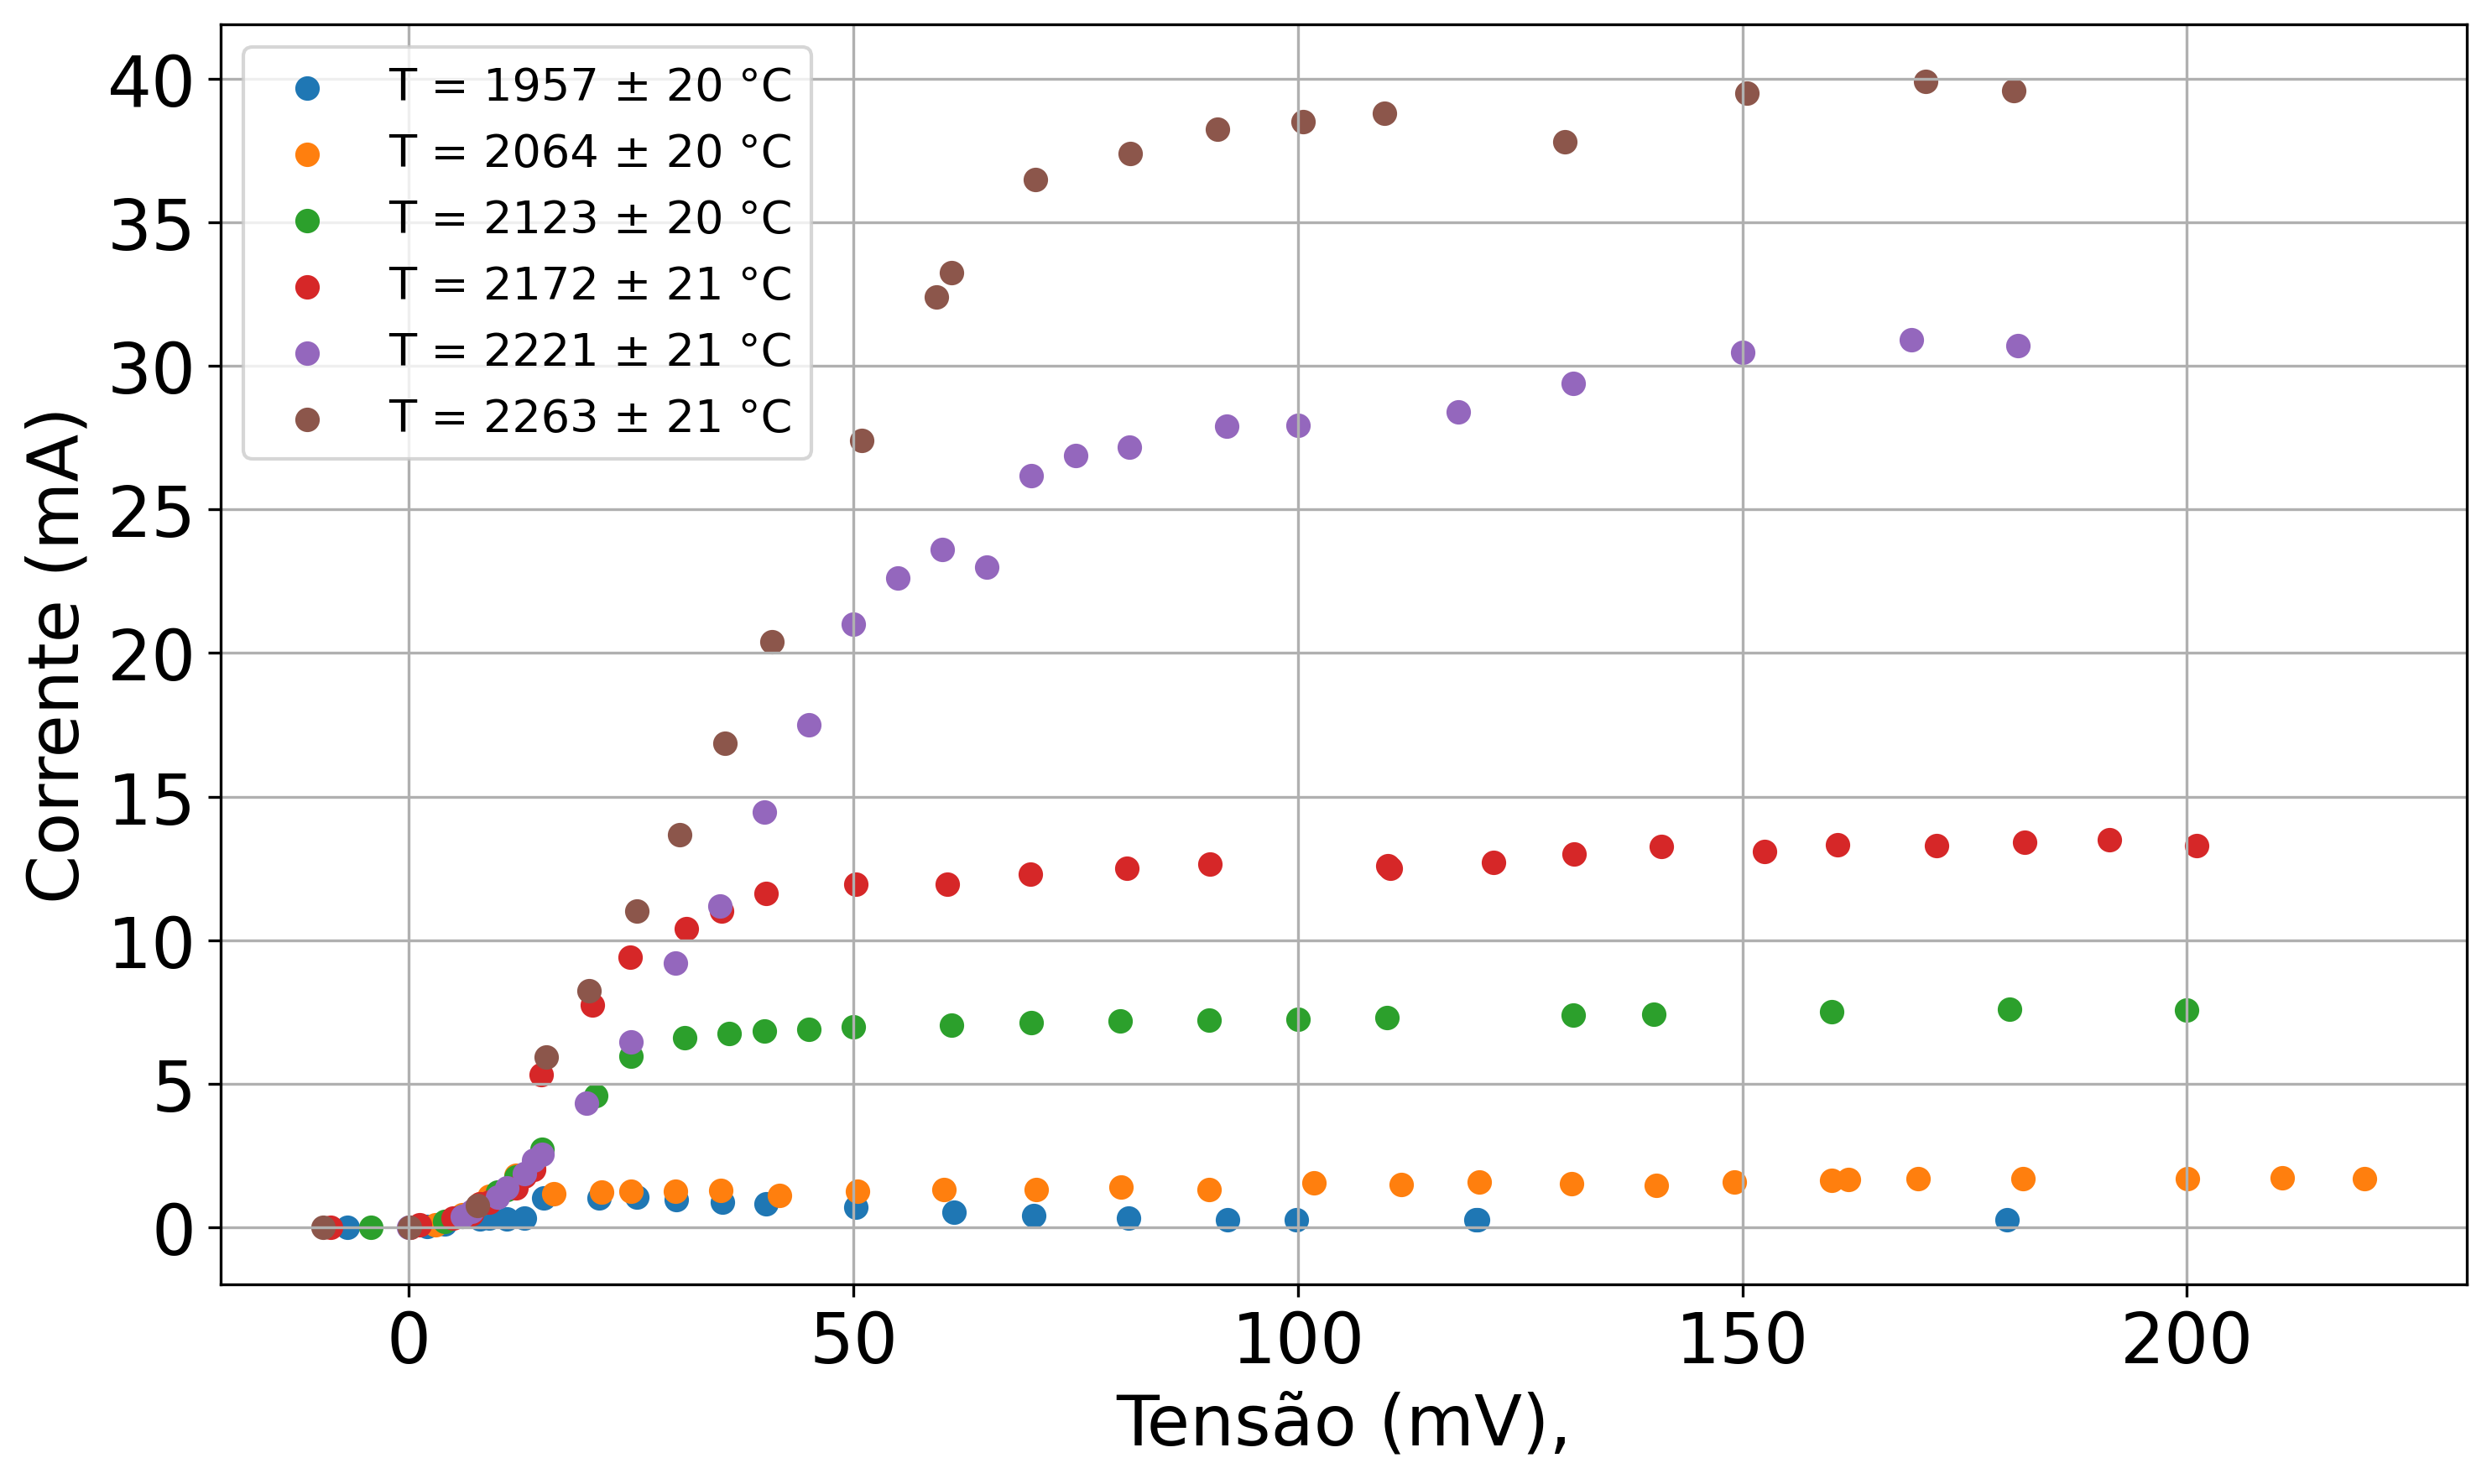

In [ ]:
df_dados = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Termoionico/Dados.csv")


plt.figure(figsize=(10, 6), dpi=300)

plt.scatter(df_dados["v = 7,05 V"], df_dados["I = 2,676 mA"], label=f"T = {int(tabela_temp["T (°C)"][0])} ± {int(tabela_temp["ΔT (°C)"][0])} °C")
plt.scatter(df_dados["V = 7,99 V"], df_dados["I = 2,878 mA"], label=f"T = {int(tabela_temp["T (°C)"][1])} ± {int(tabela_temp["ΔT (°C)"][1])} °C")
plt.scatter(df_dados["V = 8,57"], df_dados["I 3,001 mA"], label=f"T = {int(tabela_temp["T (°C)"][2])} ± {int(tabela_temp["ΔT (°C)"][2])} °C")
plt.scatter(df_dados["V 9,07 V"], df_dados["I = 3,104"], label=f"T = {int(tabela_temp["T (°C)"][3])} ± {int(tabela_temp["ΔT (°C)"][3])} °C")
plt.scatter(df_dados["V = 9,51"], df_dados["I 3,182"], label=f"T = {int(tabela_temp["T (°C)"][4])} ± {int(tabela_temp["ΔT (°C)"][4])} °C")
plt.scatter(df_dados["V = 10,01"], df_dados["I =3,286"], label=f"T = {int(tabela_temp["T (°C)"][5])} ± {int(tabela_temp["ΔT (°C)"][5])} °C")

# Rótulos e título gerais
plt.xlabel('Tensão (mV),',fontsize=20)
plt.ylabel('Corrente (mA)',fontsize=20)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=13)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
conjuntos = [
    {"df": df_dados[:9],  "V": "V = 8,57",   "I": "I 3,001 mA", "temp_idx": 2},
    {"df": df_dados[:10],  "V": "V 9,07 V",   "I": "I = 3,104",  "temp_idx": 3},
    {"df": df_dados[:15], "V": "V = 9,51",   "I": "I 3,182",    "temp_idx": 4},
    {"df": df_dados[:16], "V": "V = 10,01",  "I": "I =3,286",   "temp_idx": 5}
]
for i, c in enumerate(conjuntos):
   df = c["df"].copy()
   V = df[c["V"]].astype(float)
   I = df[c["I"]].astype(float) * 1e-3  # ✅ converte mA → A
   plt.scatter(V, I, marker= marcadores[i], label=f"{int(T)} ± {int(dT)} °C (dados)")

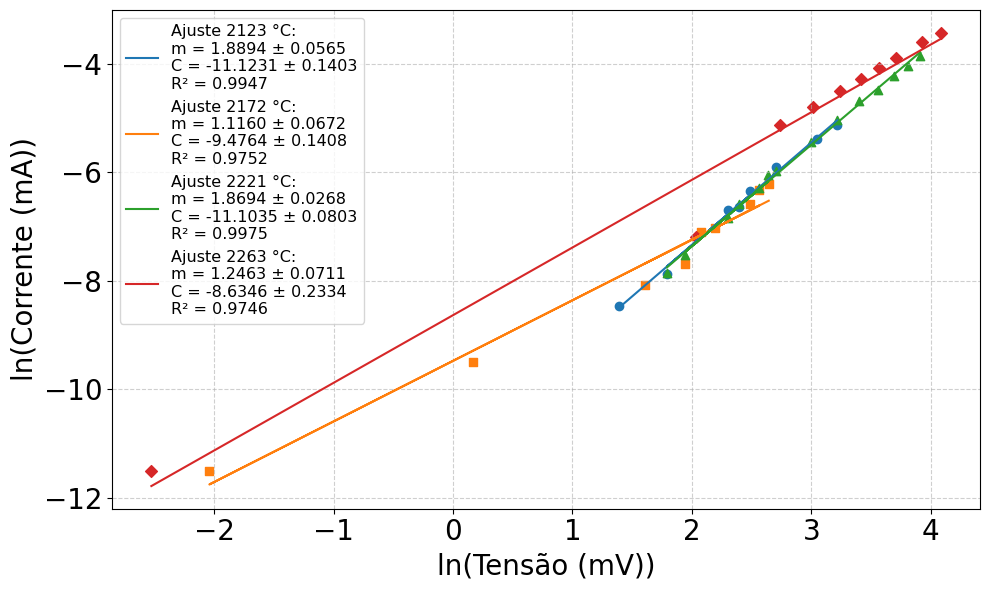


📊 Tabela de Resultados (I em A, sem incertezas):
 T (°C)  ΔT (°C)  Inclinação (m)           Δm  Intercepto (a = ln k)           Δa           R²  Constante k (A/V^m)           Δk
   2123       20    1.889378e+00 5.652334e-02          -1.112313e+01 1.403479e-01 9.946587e-01         1.476677e-05 2.072485e-06
   2172       21    1.115956e+00 6.721971e-02          -9.476352e+00 1.407577e-01 9.752312e-01         7.664301e-05 1.078810e-05
   2221       21    1.869375e+00 2.678605e-02          -1.110347e+01 8.031749e-02 9.975423e-01         1.505995e-05 1.209577e-06
   2263       21    1.246311e+00 7.107251e-02          -8.634612e+00 2.334010e-01 9.746437e-01         1.778426e-04 4.150863e-05
m (média) = 1.530255


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy import stats

# --- Subconjuntos e colunas correspondentes ---
conjuntos = [
    {"df": df_dados[:9],  "V": "V = 8,57",   "I": "I 3,001 mA", "temp_idx": 2},
    {"df": df_dados[:10],  "V": "V 9,07 V",   "I": "I = 3,104",  "temp_idx": 3},
    {"df": df_dados[:15], "V": "V = 9,51",   "I": "I 3,182",    "temp_idx": 4},
    {"df": df_dados[:16], "V": "V = 10,01",  "I": "I =3,286",   "temp_idx": 5}
]

# --- Cores e marcadores ---
marcadores = ['o', 's', '^', 'D']

resultados = []

plt.figure(figsize=(10, 6))

# --- Modelo linear: ln(I) = a + b * ln(V)
def modelo_linear(lnV, a, b):
    return a + b * lnV

for i, c in enumerate(conjuntos):
    df = c["df"].copy()
    V = df[c["V"]].astype(float)
    I = df[c["I"]].astype(float) * 1e-3  # ✅ converte mA → A

    # Remover valores não físicos
    mask = (V > 0) & (I > 0)
    V, I = V[mask], I[mask]

    # --- Transformação logarítmica ---
    lnV = np.log(V)
    lnI = np.log(I)

    # --- Ajuste linear simples (OLS) ---
    popt, pcov = curve_fit(modelo_linear, lnV, lnI)
    a, b = popt
    da, db = np.sqrt(np.diag(pcov))

    # --- Predição e R² ---
    lnI_fit = modelo_linear(lnV, *popt)
    ss_res = np.sum((lnI - lnI_fit) ** 2)
    ss_tot = np.sum((lnI - np.mean(lnI)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    # --- Constante k e incerteza ---
    k = np.exp(a)
    dk = k * da  # propagação Δk = e^a * Δa

    # --- Temperaturas ---
    T = tabela_temp["T (°C)"][c["temp_idx"]]
    dT = tabela_temp["ΔT (°C)"][c["temp_idx"]]

    # --- Plot ---
    plt.scatter(lnV, lnI, marker=marcadores[i])
    plt.plot(lnV, lnI_fit,
             label=(f"Ajuste {int(T)} °C:\n"
                    f"m = {b:.4f} ± {db:.4f}\n"
                    f"C = {a:.4f} ± {da:.4f}\n"
                    f"R² = {r2:.4f}"))

    resultados.append({
        "T (°C)": int(T),
        "ΔT (°C)": int(dT),
        "Inclinação (m)": b,
        "Δm": db,
        "Intercepto (a = ln k)": a,
        "Δa": da,
        "R²": r2,
        "Constante k (A/V^m)": k,
        "Δk": dk
    })

# --- Aparência ---
plt.xlabel('ln(Tensão (mV))', fontsize=20)
plt.ylabel('ln(Corrente (mA))', fontsize=20)
plt.tick_params(axis='both', labelsize=20)

plt.legend(fontsize=11.5, loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Tabela resumo ---
tabela_resultados = pd.DataFrame(resultados)
pd.options.display.float_format = '{:.6e}'.format

print("\n📊 Tabela de Resultados (I em A, sem incertezas):")
print(tabela_resultados.to_string(index=False))

# --- Análise estatística do expoente m ---
slopes = tabela_resultados["Inclinação (m)"].values
n = len(slopes)
mean_m = np.mean(slopes)
std_m = np.std(slopes, ddof=1)
sem_m = std_m / np.sqrt(n)

# Teste t de uma amostra contra m0 = 1.5 (valor teórico)
m0 = 1.5
t_stat, p_value = stats.ttest_1samp(slopes, m0)

print(f"m (média) = {mean_m:.6f}")



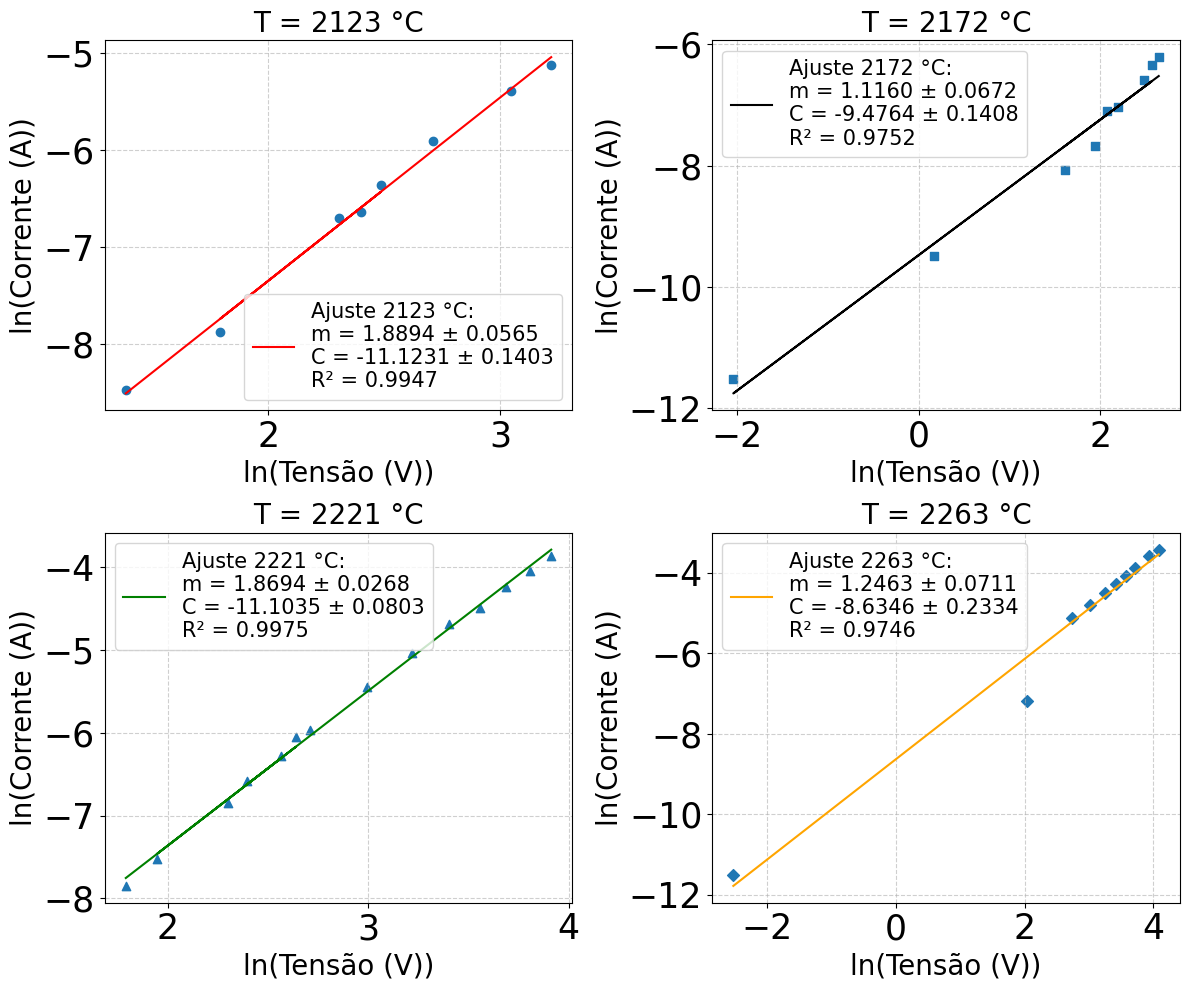


📊 Tabela de Resultados:
 T (°C)  ΔT (°C)  Inclinação (m)           Δm  Intercepto (a = ln k)           Δa           R²  Constante k (A/V^m)           Δk
   2123       20    1.889378e+00 5.652334e-02          -1.112313e+01 1.403479e-01 9.946587e-01         1.476677e-05 2.072485e-06
   2172       21    1.115956e+00 6.721971e-02          -9.476352e+00 1.407577e-01 9.752312e-01         7.664301e-05 1.078810e-05
   2221       21    1.869375e+00 2.678605e-02          -1.110347e+01 8.031749e-02 9.975423e-01         1.505995e-05 1.209577e-06
   2263       21    1.246311e+00 7.107251e-02          -8.634612e+00 2.334010e-01 9.746437e-01         1.778426e-04 4.150863e-05

m (média) = 1.530255 ± 0.203355
Teste t contra m₀ = 1.5: t = 0.149, p = 0.891


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy import stats

# --- Subconjuntos e colunas correspondentes ---
conjuntos = [
    {"df": df_dados[:9],  "V": "V = 8,57",   "I": "I 3,001 mA", "temp_idx": 2},
    {"df": df_dados[:10], "V": "V 9,07 V",   "I": "I = 3,104",  "temp_idx": 3},
    {"df": df_dados[:15], "V": "V = 9,51",   "I": "I 3,182",    "temp_idx": 4},
    {"df": df_dados[:16], "V": "V = 10,01",  "I": "I =3,286",   "temp_idx": 5}
]

marcadores = ['o', 's', '^', 'D']
resultados = []

# --- Modelo linear ---
def modelo_linear(lnV, a, b):
    return a + b * lnV

# --- Cria figura 2x2 ---
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
axs = axs.flatten()

for i, c in enumerate(conjuntos):
    df = c["df"].copy()
    V = df[c["V"]].astype(float)
    I = df[c["I"]].astype(float) * 1e-3  # mA → A

    mask = (V > 0) & (I > 0)
    V, I = V[mask], I[mask]

    lnV = np.log(V)
    lnI = np.log(I)

    popt, pcov = curve_fit(modelo_linear, lnV, lnI)
    a, b = popt
    da, db = np.sqrt(np.diag(pcov))

    lnI_fit = modelo_linear(lnV, *popt)
    ss_res = np.sum((lnI - lnI_fit) ** 2)
    ss_tot = np.sum((lnI - np.mean(lnI)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    k = np.exp(a)
    dk = k * da

    T = tabela_temp["T (°C)"][c["temp_idx"]]
    dT = tabela_temp["ΔT (°C)"][c["temp_idx"]]

    # --- Plot individual ---
    ax = axs[i]
    cores = ["red", "black", "green", "orange"]
    ax.scatter(lnV, lnI, marker=marcadores[i], color='C0')
    ax.plot(lnV, lnI_fit, color= cores[i],
             label=(f"Ajuste {int(T)} °C:\n"
                    f"m = {b:.4f} ± {db:.4f}\n"
                    f"C = {a:.4f} ± {da:.4f}\n"
                    f"R² = {r2:.4f}"))

    ax.set_xlabel('ln(Tensão (V))', fontsize=20)
    ax.set_ylabel('ln(Corrente (A))', fontsize=20)
    ax.tick_params(axis='both', labelsize=25)
    ax.legend(fontsize=15, loc='best')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_title(f"T = {int(T)} °C", fontsize=20)

    resultados.append({
        "T (°C)": int(T),
        "ΔT (°C)": int(dT),
        "Inclinação (m)": b,
        "Δm": db,
        "Intercepto (a = ln k)": a,
        "Δa": da,
        "R²": r2,
        "Constante k (A/V^m)": k,
        "Δk": dk
    })

plt.tight_layout()
plt.show()

# --- Tabela resumo ---
tabela_resultados = pd.DataFrame(resultados)
pd.options.display.float_format = '{:.6e}'.format
print("\n📊 Tabela de Resultados:")
print(tabela_resultados.to_string(index=False))

# --- Estatística do expoente m ---
slopes = tabela_resultados["Inclinação (m)"].values
mean_m = np.mean(slopes)
std_m = np.std(slopes, ddof=1)
sem_m = std_m / np.sqrt(len(slopes))

m0 = 1.5
t_stat, p_value = stats.ttest_1samp(slopes, m0)
print(f"\nm (média) = {mean_m:.6f} ± {sem_m:.6f}")
print(f"Teste t contra m₀ = {m0}: t = {t_stat:.3f}, p = {p_value:.3f}")


In [ ]:
# --- Constante física ---
eps0 = 8.8541878128e-12  # F/m (permissividade do vácuo)

# --- Geometria do tubo (em metros) ---
diam = 29.5e-3      # 29,5 mm
ddiam = 0.3e-3      # ±0,3 mm


l = 93e-3           # 93 mm
dl = 1e-3           # ±1 mm

ra = diam / 2
dra = ddiam / 2


# --- Constante k e sua incerteza (substitua pelos seus valores experimentais) ---
k_values = np.array([0.000014767, 7.664301e-05, 0.000015060, 1.778426e-04])  # A/V^(3/2)
dk_values = np.array([2.072485e-06, 1.078810e-05, 1.209577e-06, 4.150863e-05])

# --- Cálculo do C' ---
C = (8 * np.pi * eps0 * l) / (9 * ra)
dC_rel = np.sqrt((dl / l)**2 + (dra / ra)**2)

# --- Cálculo de e/m ---
em_values = (k_values**2) / (2 * C**2)
# Incerteza relativa de k (a partir dos valores dados)
dk_rel = dk_values / k_values
# Incerteza de e/m propagada
dem_values = em_values * np.sqrt((2 * dk_rel)**2 + (2 * dC_rel)**2)

# --- Valor teórico ---
em_teorico = 1.758820e11
erro_rel_percent = 100 * (em_values - em_teorico) / em_teorico

# --- Média ponderada de e/m ---
weights = 1 / (dem_values**2)
em_media = np.sum(em_values) / 4
dem_media = np.sum(dem_values) / 4

# --- Tabela de resultados individuais ---
df_em = pd.DataFrame({
    "k (A/V^(3/2))": k_values,
    "Δk": dk_values,
    "e/m (C/kg)": em_values,
    "Δ(e/m)": dem_values,
    "Erro rel (%)": erro_rel_percent
})

pd.options.display.float_format = "{:.3e}".format
print(df_em)

# --- Resultados médios ---
print("\n--- Média ponderada ---")
print(f"e/m médio = ({em_media:.3e} ± {dem_media:.3e}) C/kg")
print(f"Erro relativo da média = {100 * abs(em_media - em_teorico) / em_teorico:.2f}%")
print(f"Valor teórico = {em_teorico:.3e} C/kg")
print(f"C' = {C:.3e} ± {C * dC_rel:.3e}")


   k (A/V^(3/2))        Δk  e/m (C/kg)    Δ(e/m)  Erro rel (%)
0      1.477e-05 2.072e-06   4.486e+09 1.266e+09    -9.745e+01
1      7.664e-05 1.079e-05   1.208e+11 3.421e+10    -3.129e+01
2      1.506e-05 1.210e-06   4.666e+09 7.621e+08    -9.735e+01
3      1.778e-04 4.151e-05   6.507e+11 3.043e+11     2.700e+02

--- Média ponderada ---
e/m médio = (1.952e+11 ± 8.515e+10) C/kg
Erro relativo da média = 10.97%
Valor teórico = 1.759e+11 C/kg
C' = 1.559e-10 ± 2.307e-12


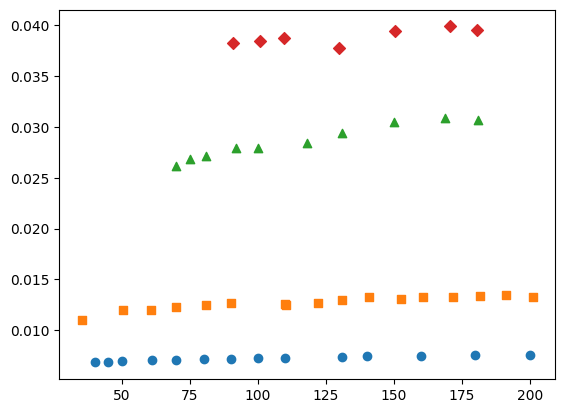

In [ ]:

# --- Subconjuntos e colunas correspondentes ---
conjuntos = [
    {"df": df_dados[11:],  "V": "V = 8,57",   "I": "I 3,001 mA", "temp_idx": 2},
    {"df": df_dados[15:],  "V": "V 9,07 V",   "I": "I = 3,104",  "temp_idx": 3},
    {"df": df_dados[18:], "V": "V = 9,51",   "I": "I 3,182",    "temp_idx": 4},
    {"df": df_dados[19:], "V": "V = 10,01",  "I": "I =3,286",   "temp_idx": 5}
]

for i, c in enumerate(conjuntos):
   df = c["df"].copy()
   V = df[c["V"]].astype(float)
   I = df[c["I"]].astype(float) * 1e-3  # ✅ converte mA → A
   plt.scatter(V, I, marker=marcadores[i], label=f"{int(T)} ± {int(dT)} °C (dados)")

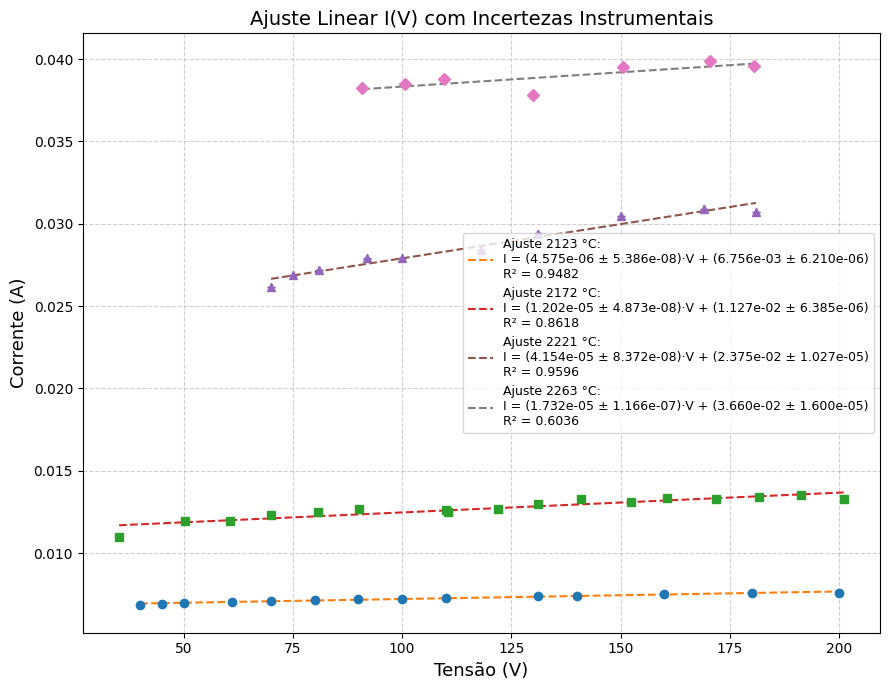


📊 Tabela de Resultados (ajuste ponderado I = aV + b):
 T (°C)  ΔT (°C)  Inclinação (a)           Δa  Intercepto (b)           Δb           R²
   2123       20    4.574567e-06 5.385776e-08    6.756061e-03 6.209629e-06 9.482272e-01
   2172       21    1.201550e-05 4.873043e-08    1.126894e-02 6.384989e-06 8.618061e-01
   2221       21    4.154477e-05 8.371763e-08    2.374672e-02 1.026888e-05 9.595860e-01
   2263       21    1.731900e-05 1.166435e-07    3.659926e-02 1.599652e-05 6.036380e-01


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

# --- Função linear para o ajuste ---
def modelo_linear(V, a, b):
    return a * V + b

# --- Incertezas instrumentais ---
# (ajuste conforme os instrumentos do experimento)
dV = 0.01     # incerteza do voltímetro em V
dI = 0.00001  # incerteza do amperímetro em A (≈ 0,01 mA)

# --- Subconjuntos e colunas correspondentes ---

# {"df": df_dados[:3],  "V": "v = 7,05 V",  "I": "I = 2,676 mA", "temp_idx": 0},
# {"df": df_dados[6:],  "V": "V = 7,99 V",   "I": "I = 2,878 mA", "temp_idx": 1},

conjuntos = [
    {"df": df_dados[11:],  "V": "V = 8,57",   "I": "I 3,001 mA", "temp_idx": 2},
    {"df": df_dados[15:],  "V": "V 9,07 V",   "I": "I = 3,104",  "temp_idx": 3},
    {"df": df_dados[18:],  "V": "V = 9,51",   "I": "I 3,182",    "temp_idx": 4},
    {"df": df_dados[19:],  "V": "V = 10,01",  "I": "I =3,286",   "temp_idx": 5}
]

# --- Cores e marcadores ---
marcadores = ['o', 's', '^', 'D']

resultados = []

plt.figure(figsize=(9, 7))
plt.title("Ajuste Linear I(V) com Incertezas Instrumentais", fontsize=14)
plt.xlabel("Tensão (V)", fontsize=13)
plt.ylabel("Corrente (A)", fontsize=13)

for i, c in enumerate(conjuntos):
    df = c["df"].copy()

    # --- Seleção e limpeza de dados ---
    V = df[c["V"]].astype(float)
    I = df[c["I"]].astype(float) * 1e-3  # mA → A
    mask = (~np.isnan(V)) & (~np.isnan(I))
    V, I = V[mask], I[mask]

    if len(V) < 2:
        print(f"⚠️ Conjunto {i+1} tem poucos dados válidos, ignorado.")
        continue

    # --- Pesos (incertezas de I dominam normalmente) ---
    sigma_I = np.full_like(I, dI)

    # --- Ajuste ponderado ---
    popt, pcov = curve_fit(modelo_linear, V, I, sigma=sigma_I, absolute_sigma=True)
    a, b = popt
    da, db = np.sqrt(np.diag(pcov))

    # --- R² (coeficiente de determinação) ---
    I_fit = modelo_linear(V, *popt)
    ss_res = np.sum((I - I_fit) ** 2)
    ss_tot = np.sum((I - np.mean(I)) ** 2)
    r2 = 1 - ss_res / ss_tot

    # --- Temperatura correspondente ---
    T = tabela_temp["T (°C)"][c["temp_idx"]]
    dT = tabela_temp["ΔT (°C)"][c["temp_idx"]]

    # --- Predição para gráfico ---
    V_fit = np.linspace(V.min(), V.max(), 100)
    I_fit_plot = modelo_linear(V_fit, *popt)

    # --- Plot ---
    plt.errorbar(V, I, xerr=dV, yerr=dI, fmt=marcadores[i],
                  capsize=3, linestyle='none')
    plt.plot(V_fit, I_fit_plot, linestyle='--',
             label=(f"Ajuste {int(T)} °C:\n"
                    f"I = ({a:.3e} ± {da:.3e})·V + ({b:.3e} ± {db:.3e})\n"
                    f"R² = {r2:.4f}"))

    # --- Armazenar resultados ---
    resultados.append({
        "T (°C)": int(T),
        "ΔT (°C)": int(dT),
        "Inclinação (a)": a,
        "Δa": da,
        "Intercepto (b)": b,
        "Δb": db,
        "R²": r2
    })

plt.legend(fontsize=9, loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Tabela resumo ---
tabela_resultados = pd.DataFrame(resultados)
pd.options.display.float_format = '{:.6e}'.format

print("\n📊 Tabela de Resultados (ajuste ponderado I = aV + b):")
print(tabela_resultados.to_string(index=False))


A0 teórico = 1.2017e+06 A·m⁻²·K⁻²
Área (cilíndrica) = 8.618959e-03 ± 1.28e-04 m²
Slope = -7.0440e+04 ± 4.3852e+03 (1/K)
Intercept = 1.3556e+01 ± 1.7782e+00
Função trabalho φ = 6.0700 ± 0.3779 eV


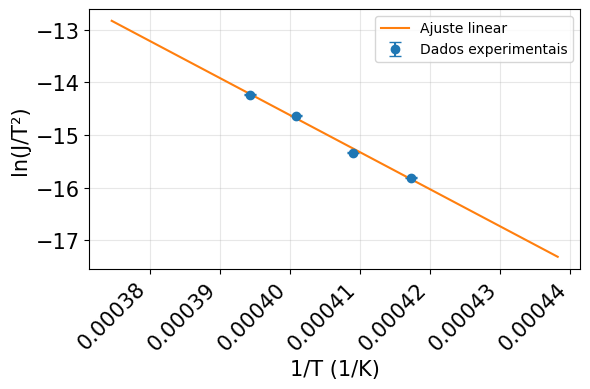

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constantes físicas
k_B = 1.380649e-23       # J/K
e_charge = 1.602176634e-19  # C
h = 6.62607015e-34       # J·s
m_e = 9.10938356e-31     # kg

# Constante teórica de Richardson
A0_theoretical = 4 * np.pi * m_e * e_charge * (k_B**2) / (h**3)

# ====================== DADOS EXPERIMENTAIS ======================
T_data = np.array([2396.0, 2445.0, 2494.0, 2536.0])     # K
T_data_err = np.array([20, 21, 21, 21])                 # K
I_data = np.array([6.756061e-03, 1.126894e-02, 2.374672e-02, 3.659926e-02])  # A
I_data_err = np.array([6.209629e-06, 6.384989e-06, 1.026888e-05, 1.599652e-05])  # A

# ====================== GEOMETRIA CILÍNDRICA ======================
diam = 29.5e-3    # m
ddiam = 0.3e-3    # m
l = 93e-3         # m
dl = 1e-3         # m

# Área do coletor (cilindro)
A = np.pi * diam * l
sigma_A = A * np.sqrt((ddiam/diam)**2 + (dl/l)**2)

# ====================== DENSIDADE DE CORRENTE ======================
J = I_data / A
sigma_J = J * np.sqrt((I_data_err/I_data)**2 + (sigma_A/A)**2)

# ====================== AJUSTE LINEAR (Richardson-Dushman) ======================
x = 1 / T_data
y = np.log(J / T_data**2)

# Propagação do erro em y ≈ σ_J/J
sigma_y = sigma_J / J

# Ajuste linear ponderado (com pesos = 1/σ_y²)
weights = 1 / sigma_y**2
p, cov = np.polyfit(x, y, 1, w=np.sqrt(weights), cov=True)
slope, intercept = p
slope_err, intercept_err = np.sqrt(np.diag(cov))

# ====================== CÁLCULOS DE φ ======================
phi_J = -slope * k_B
phi_eV = phi_J / e_charge
sigma_phi_J = k_B * slope_err
sigma_phi_eV = sigma_phi_J / e_charge

# ====================== RESULTADOS ======================
print(f"A0 teórico = {A0_theoretical:.4e} A·m⁻²·K⁻²")
print(f"Área (cilíndrica) = {A:.6e} ± {sigma_A:.2e} m²")
print(f"Slope = {slope:.4e} ± {slope_err:.4e} (1/K)")
print(f"Intercept = {intercept:.4e} ± {intercept_err:.4e}")
print(f"Função trabalho φ = {phi_eV:.4f} ± {sigma_phi_eV:.4f} eV")

# ====================== GRÁFICO ======================
plt.figure(figsize=(6,4))
plt.errorbar(x, y, yerr=sigma_y, fmt='o', capsize=4, label='Dados experimentais')
x_line = np.linspace(min(x)*0.95, max(x)*1.05, 200)
y_line = slope * x_line + intercept
plt.plot(x_line, y_line, '-', label='Ajuste linear')
plt.xlabel('1/T (1/K)', fontsize=15)
plt.ylabel('ln(J/T²)', fontsize=15)
plt.tick_params(labelsize=15)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Área do filamento: 8.618959e-03 m²

Densidades de corrente:
T = 2396.0 K: J0 = 7.838604e-01 ± 7.204616e-04 A/m²
T = 2445.0 K: J0 = 1.307459e+00 ± 7.408074e-04 A/m²
T = 2494.0 K: J0 = 2.755172e+00 ± 1.191429e-03 A/m²
T = 2536.0 K: J0 = 4.246366e+00 ± 1.855969e-03 A/m²

Dados para gráfico de Richardson:
1/T = 4.173623e-04 K⁻¹, ln(J0/T²) = -15.807 ± 0.017
1/T = 4.089980e-04 K⁻¹, ln(J0/T²) = -15.336 ± 0.017
1/T = 4.009623e-04 K⁻¹, ln(J0/T²) = -14.630 ± 0.017
1/T = 3.943218e-04 K⁻¹, ln(J0/T²) = -14.231 ± 0.017

Resultados da regressão linear:
Inclinação (m) = -70436.271 ± 4383.468 K
Intercepto = 13.555 ± 1.778

--- RESULTADO FINAL ---
Função trabalho φ = 6.070 ± 0.378 eV
Constante de Richardson A = 7.707e+05 A/(m²K²)


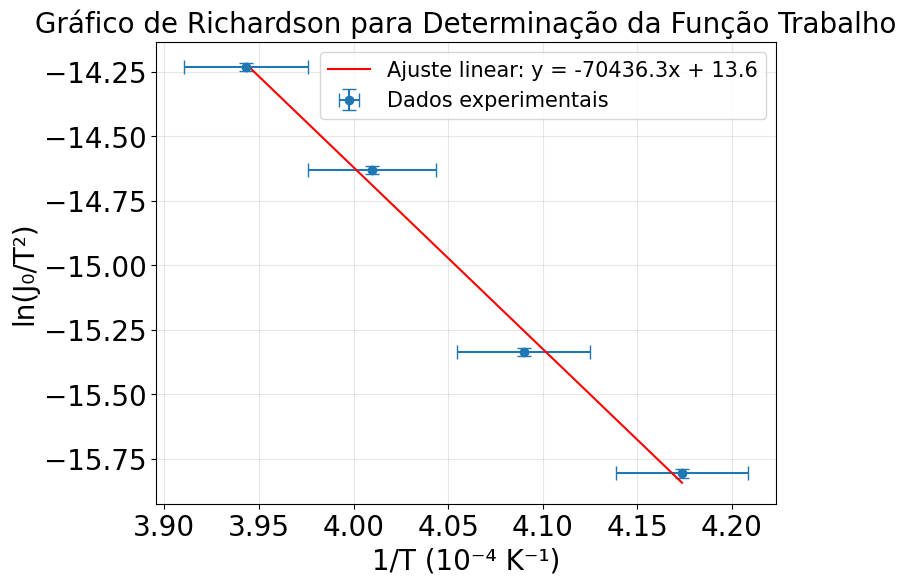


Equação da reta: ln(J₀/T²) = (-70436.3 ± 4383.5) × (1/T) + (13.6 ± 1.8)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Dados experimentais
T_data = np.array([2396.0, 2445.0, 2494.0, 2536.0])     # K
T_data_err = np.array([20, 21, 21, 21])                 # K
I_data = np.array([6.756061e-03, 1.126894e-02, 2.374672e-02, 3.659926e-02])  # A
I_data_err = np.array([6.209629e-06, 6.384989e-06, 1.026888e-05, 1.599652e-05])  # A

# Geometria do filamento
diametro_anodo = 29.5e-3    # m
comprimento_filamento = 93e-3  # m

# Constantes físicas
k_B = 8.617333262145e-5  # eV/K (constante de Boltzmann)

# 1. Calcular área superficial do filamento
# Considerando que os elétrons são emitidos por toda a superfície lateral
area_filamento = np.pi * diametro_anodo * comprimento_filamento  # m²
print(f"Área do filamento: {area_filamento:.6e} m²")

# 2. Calcular densidade de corrente J0 = I_sat / A
J0_data = I_data / area_filamento  # A/m²
J0_err = I_data_err / area_filamento  # A/m²

print("\nDensidades de corrente:")
for i in range(len(T_data)):
    print(f"T = {T_data[i]} K: J0 = {J0_data[i]:.6e} ± {J0_err[i]:.6e} A/m²")

# 3. Preparar dados para gráfico de Richardson
# y = ln(J0/T²), x = 1/T
y_data = np.log(J0_data / T_data**2)
x_data = 1 / T_data

# Propagação de erro para y
y_err = np.sqrt((J0_err/J0_data)**2 + (2*T_data_err/T_data)**2)

print(f"\nDados para gráfico de Richardson:")
for i in range(len(T_data)):
    print(f"1/T = {x_data[i]:.6e} K⁻¹, ln(J0/T²) = {y_data[i]:.3f} ± {y_err[i]:.3f}")

# 4. Regressão linear
regressao = linregress(x_data, y_data)
inclinacao = regressao.slope
erro_inclinacao = regressao.stderr
intercepto = regressao.intercept
erro_intercepto = regressao.intercept_stderr

print(f"\nResultados da regressão linear:")
print(f"Inclinação (m) = {inclinacao:.3f} ± {erro_inclinacao:.3f} K")
print(f"Intercepto = {intercepto:.3f} ± {erro_intercepto:.3f}")

# 5. Calcular função trabalho
# m = -φ/k_B → φ = -m * k_B
funcao_trabalho = -inclinacao * k_B  # eV
erro_funcao_trabalho = erro_inclinacao * k_B  # eV

print(f"\n--- RESULTADO FINAL ---")
print(f"Função trabalho φ = {funcao_trabalho:.3f} ± {erro_funcao_trabalho:.3f} eV")

# 6. Constante de Richardson
constante_richardson = np.exp(intercepto)
print(f"Constante de Richardson A = {constante_richardson:.3e} A/(m²K²)")

# 7. Plotar gráfico de Richardson
plt.figure(figsize=(8, 6))
plt.errorbar(x_data * 1e4, y_data, xerr=(T_data_err/T_data**2)*1e4, yerr=y_err,
             fmt='o', capsize=5, label='Dados experimentais')

# Linha de melhor ajuste
x_fit = np.linspace(min(x_data), max(x_data), 100)
y_fit = inclinacao * x_fit + intercepto
plt.plot(x_fit * 1e4, y_fit, 'r-', label=f'Ajuste linear: y = {inclinacao:.1f}x + {intercepto:.1f}')

plt.xlabel('1/T (10⁻⁴ K⁻¹)', fontsize=20)
plt.ylabel('ln(J₀/T²)', fontsize=20)
plt.title('Gráfico de Richardson para Determinação da Função Trabalho', fontsize=20)
plt.legend(fontsize=15)
plt.tick_params(labelsize=20)
plt.grid(True, alpha=0.3)
plt.show()

# 8. Mostrar equação da reta
print(f"\nEquação da reta: ln(J₀/T²) = ({inclinacao:.1f} ± {erro_inclinacao:.1f}) × (1/T) + ({intercepto:.1f} ± {erro_intercepto:.1f})")

0     0.104
1     0.201
2     0.301
3     0.404
4     0.415
5     0.507
6     0.622
7     0.650
8     0.668
9     0.704
10    0.731
11    0.770
12    0.789
13    0.803
14    0.847
15    0.902
16    1.190
17    1.250
18    1.220
19    1.300
Name: I(bobina)  10V, 2,34 A, dtype: float64


Text(0.5, 1.0, 'I(bobina) x I (coletor)')

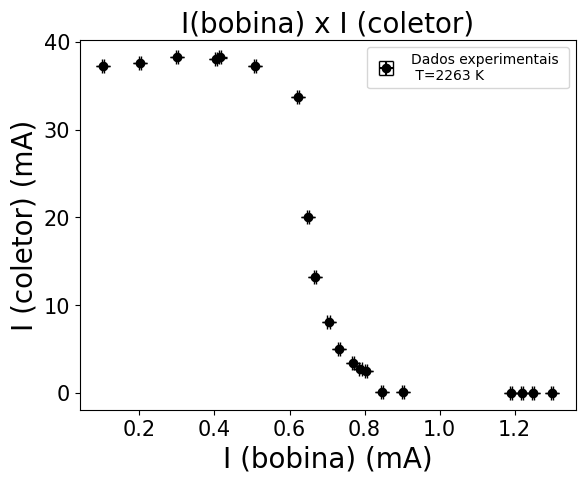

In [ ]:
url_bobina = "/content/drive/MyDrive/2025s2/F 740/Termoionico/bobina.csv"

df_bobina = pd.read_csv(url_bobina, header=1)
err = [0.002886, 0.002886, 0.002886, 0.002886, 0.002886,
        0.002886, 0.002886, 0.002886, 0.002886, 0.002886,
        0.002886, 0.002886, 0.002886, 0.002886, 0.002886,
        0.002886, 0.002886, 0.002886, 0.002886, 0.002886]
# plt.scatter(df_bobina["I(bobina) 8,54 V 2,79 A"], df_bobina["I (coletor) 8,54 V 2,79 A"], c='r', label='Dados experimentais \n T=2123 K ')

plt.errorbar(df_bobina["I(bobina)  10V, 2,34 A"], df_bobina["I (coletor) 10V, 2,34 A"], xerr=err, yerr=err, fmt='o', c='k', label='Dados experimentais \n T=2263 K ', capsize=5)
plt.legend()
print(df_bobina["I(bobina)  10V, 2,34 A"])
plt.xlabel("I (bobina) (mA)", fontsize=20)
plt.ylabel("I (coletor) (mA)", fontsize=20)
plt.tick_params(labelsize=15)
plt.title("I(bobina) x I (coletor)", fontsize=20)

In [ ]:
import numpy as np

# seus dados
I = np.array([
    0.104, 0.201, 0.301, 0.404, 0.415,
    0.507, 0.622, 0.650, 0.668, 0.704,
    0.731, 0.770, 0.789, 0.803, 0.847,
    0.902, 1.190, 1.250, 1.220, 1.300
])

# estima o platô antes e depois da queda (por média dos primeiros e últimos pontos)
I_alto = np.mean(I[:6])   # primeiros valores (platô alto)
I_baixo = np.mean(I[-6:]) # últimos valores (platô baixo)

# ponto médio entre os platôs
I_medio = 0.5 * (I_alto + I_baixo)

print("Platô alto:", I_alto)
print("Platô baixo:", I_baixo)
print("Média entre platôs:", I_medio)


Platô alto: 0.322
Platô baixo: 1.1181666666666665
Média entre platôs: 0.7200833333333333


In [ ]:
# Valores e incertezas
# --- Constantes físicas ---
mu0 = 4 * np.pi * 1e-7  # permeabilidade do vácuo [T·m/A]

# --- Dados da bobina ---
N = 812                 # número de espiras
D = 8e-2
v0 = 105
L = 11.5e-2
I = 0.668
v0_err = 1 / np.sqrt(3)
bc = (mu0 * I * N) / (D**2 + L**2)**(1/2)
bc_err = 0.0006
ra = (29.5e-3) / 2
ra_err = 0.3e-3

# Valor principal
resultado = (8 * v0) / (bc**2 * ra**2)

# Propagação de incertezas (relativa)
rel_err = np.sqrt(
    (v0_err / v0)**2 +
    (2 * bc_err / bc)**2 +
    (2 * ra_err / ra)**2
)
resultado_err = resultado * rel_err

# Exibir resultado
print(f"Resultado: ({resultado:.3e} ± {resultado_err:.3e})")
print(f"Incerteza relativa: {rel_err*100:.2f}%")
# 1,758x10^{11} C/kg

Resultado: (1.631e+11 ± 4.078e+10)
Incerteza relativa: 25.00%


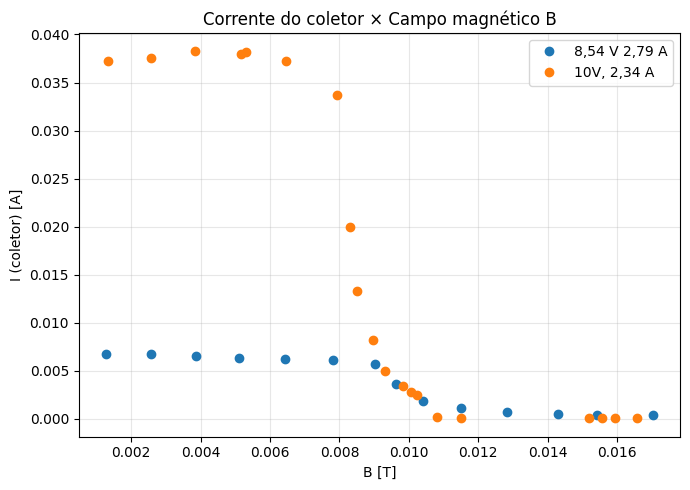

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Constantes físicas ---
mu0 = 4 * np.pi * 1e-7  # permeabilidade do vácuo [T·m/A]

# --- Dados da bobina ---
N = 812                 # número de espiras
D = 8e-2                # diametro da bobina [m]


# --- Importar CSV ---
url_bobina = "/content/drive/MyDrive/2025s2/F 740/Termoionico/bobina.csv"
df_bobina = pd.read_csv(url_bobina, header=1)

# --- Identificar colunas válidas ---
colunas_bobina = [c for c in df_bobina.columns if "I(bobina)" in c]
colunas_coletor = [c for c in df_bobina.columns if "I (coletor)" in c]

# --- Segundo gráfico: B × I(coletor) ---
plt.figure(figsize=(7,5))

for i, (col_b, col_c) in enumerate(zip(colunas_bobina, colunas_coletor)):
    # Correntes
    I_bobina = df_bobina[col_b].astype(float)
    I_coletor = df_bobina[col_c].astype(float) * 1e-3  # ✅ converte de mA → A

    # Campo magnético e incerteza
    B = mu0 * (N / D) * I_bobina
    # Plot
    plt.errorbar(B, I_coletor, fmt='o', capsize=3,
                 label=f"{col_b.split(')')[1].strip()}")

plt.xlabel("B [T]")
plt.ylabel("I (coletor) [A]")
plt.title("Corrente do coletor × Campo magnético B")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


------------------------------------------------------------
Par: bobina='I(bobina) 8,54 V 2,79 A'  coletor='I (coletor) 8,54 V 2,79 A'
N = 812, D = 8.000e-02 m, dD = 3.000e-04 m
Exemplo (médias): I_bobina = 7.125e-04 A, I_coletor = 3.785e+00 A
k = mu0 * N / D = 1.275e-02 T/A
Campo médio B = 9.088e-06 ± 1.331e-07 T (média dos pontos)
Nenhum ponto de saturação claro detectado com o critério atual.
Tente reduzir 'sat_fraction' ou aumentar 'min_plateau_points' para detectar plateaus menores.
------------------------------------------------------------
Par: bobina='I(bobina)  10V, 2,34 A'  coletor='I (coletor) 10V, 2,34 A'
N = 812, D = 8.000e-02 m, dD = 3.000e-04 m
Exemplo (médias): I_bobina = 7.189e-04 A, I_coletor = 1.579e+01 A
k = mu0 * N / D = 1.275e-02 T/A
Campo médio B = 9.169e-06 ± 1.330e-07 T (média dos pontos)
Ponto de saturação detectado:
 B_sat = 7.301e-06 ± 6.162e-07 T
 I_c,sat = 2.848e+01 ± 5.005e+00 A


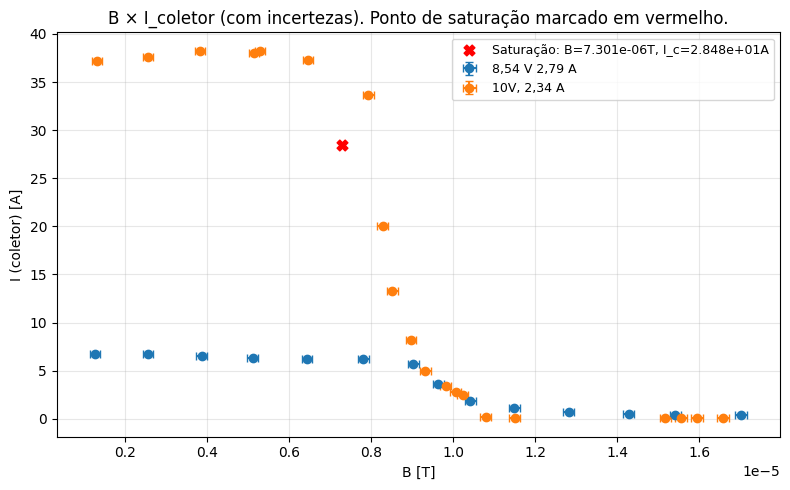


Resumo (por par de colunas):
                  col_b                     col_c  k_T_per_A    B_mean  B_mean_err     B_sat  B_sat_err    Ic_sat  Ic_sat_err  sat_found
I(bobina) 8,54 V 2,79 A I (coletor) 8,54 V 2,79 A  1.275e-02 9.088e-06   1.331e-07       NaN        NaN       NaN         NaN      False
 I(bobina)  10V, 2,34 A   I (coletor) 10V, 2,34 A  1.275e-02 9.169e-06   1.330e-07 7.301e-06  6.162e-07 2.848e+01   5.005e+00       True


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------
# Configurações / parâm.
# -----------------------
url_bobina = "/content/drive/MyDrive/2025s2/F 740/Termoionico/bobina.csv"
N = 812                # espiras (fornecido)
D = 8e-2               # diâmetro da bobina [m] (você tinha D = 8e-2)
# Incertezas (ajuste conforme seus instrumentos)
dD = 0.3e-3            # incerteza do diâmetro [m] (ex: 0.3 mm)
dI_bobina = 0.01e-3    # incerteza da medida da corrente da bobina [A] (ex: 0.01 mA)
dI_coletor = 0.01e-3   # incerteza da medida da corrente do coletor [A] (ex: 0.01 mA)
# Critério de saturação (ajustável)
sat_fraction = 0.10    # saturação quando derivada < sat_fraction * derivada_inicial
min_plateau_points = 3 # mínimo de pontos consecutivos para considerar "plateau"
# -----------------------

# constantes
mu0 = 4 * np.pi * 1e-7  # T·m/A

# --- Ler CSV ---
df_bobina = pd.read_csv(url_bobina, header=1)

# --- identificar colunas ---
colunas_bobina = [c for c in df_bobina.columns if "I(bobina)" in c]
colunas_coletor = [c for c in df_bobina.columns if "I (coletor)" in c]

if len(colunas_bobina) == 0 or len(colunas_coletor) == 0:
    raise RuntimeError("Não foram encontradas colunas de bobina ou coletor no CSV. Verifique nomes das colunas.")

# --- Concatenar/usar pares correspondentes (zip) ---
# Se houver mais colunas em uma lista, zip para pares.
# O script assume que cada par col_b, col_c está relacionado.
pairs = list(zip(colunas_bobina, colunas_coletor))

# Para saída consolidada
all_results = []

# Plota B vs I_coletor para todos pares (mas principal interesse no primeiro par)
plt.figure(figsize=(8,5))

for (col_b, col_c) in pairs:
    # extrair e converter (bobina pode estar em mA ou A, detecte pela magnitude média)
    I_bobina_raw = df_bobina[col_b].astype(float)
    I_coletor_raw = df_bobina[col_c].astype(float)

    # remover NaN
    mask = (~I_bobina_raw.isna()) & (~I_coletor_raw.isna())
    I_bobina_raw = I_bobina_raw[mask].values
    I_coletor_raw = I_coletor_raw[mask].values

    # detectar unidade - frequentemente os dados estão em mA; se média > 1 A então já está em A
    # aqui assumimos que valores típicos são mA; se média > 1 então não convertemos
    def convert_mA_to_A(arr):
        if np.nanmean(np.abs(arr)) > 1.0:     # média >1 -> possivelmente já A
            return arr.astype(float)
        else:
            return arr.astype(float) * 1e-3  # converte mA -> A

    I_bobina = convert_mA_to_A(I_bobina_raw)
    I_coletor = convert_mA_to_A(I_coletor_raw)

    # --- calcular B usando a sua fórmula (usando D no denominador como no seu trecho) ---
    # B = mu0 * (N / D) * I_bobina
    B = mu0 * (N / D) * I_bobina

    # --- propagar incertezas em B ---
    # B = mu0 * N/D * I  -> relativa: sigma_B/B = sqrt( (sigma_I/I)^2 + (sigma_D/D)^2 )
    # (assumimos sigma_N = 0, N conhecido sem incerteza)
    sigma_B = np.abs(B) * np.sqrt((dI_bobina / np.where(I_bobina==0, 1e-30, I_bobina))**2 + (dD / D)**2)

    # incerteza em I_coletor
    sigma_Ic = np.full_like(I_coletor, dI_coletor)

    # --- ordenar por B (útil para derivadas) ---
    order = np.argsort(B)
    B_sorted = B[order]
    Ic_sorted = I_coletor[order]
    sigma_B_sorted = sigma_B[order]
    sigma_Ic_sorted = sigma_Ic[order]

    # --- calcular derivada dI_c/dB (numérica) e suavizar com média móvel ---
    # deriv = dI/dB
    # usamos gradient para derivada numérica
    dIc_dB = np.gradient(Ic_sorted, B_sorted)
    # suavização por média móvel (janela odd)
    window = 5
    if len(dIc_dB) >= window:
        kernel = np.ones(window) / window
        dIc_dB_smooth = np.convolve(dIc_dB, kernel, mode='same')
    else:
        dIc_dB_smooth = dIc_dB.copy()

    # --- critério de saturação ---
    # definimos derivada inicial como média dos primeiros m pontos (ignorando zeros)
    init_mask = ~np.isnan(dIc_dB_smooth)
    if np.any(init_mask):
        # pegar primeiro valor característico: média das primeiras min(3,len) pontos
        n_init = min(3, len(dIc_dB_smooth))
        init_deriv = np.nanmean(dIc_dB_smooth[:n_init])
    else:
        init_deriv = 0.0

    # saturação quando dIc_dB_smooth < sat_fraction * init_deriv (para init_deriv>0)
    sat_indices = []
    if init_deriv > 0:
        threshold = sat_fraction * init_deriv
        below = dIc_dB_smooth <= threshold
        # procurar sequência de pontos consecutivos com length >= min_plateau_points
        consec = 0
        for idx, val in enumerate(below):
            if val:
                consec += 1
            else:
                if consec >= min_plateau_points:
                    # adiciona o índice do início do plateau encontrado
                    start_idx = idx - consec
                    sat_indices.append(start_idx)
                consec = 0
        # terminar caso sequência no fim
        if consec >= min_plateau_points:
            start_idx = len(below) - consec
            sat_indices.append(start_idx)

    # determinar ponto de saturação (se houver)
    if len(sat_indices) > 0:
        # escolhemos a primeira sequência detectada
        start = sat_indices[0]
        # definir B_sat e I_sat como médias sobre a região de plateau (start .. start+consec-1)
        # aqui usamos min_plateau_points pontos a partir do start
        end = min(start + max(min_plateau_points, 5), len(B_sorted))
        B_sat = np.mean(B_sorted[start:end])
        Ic_sat = np.mean(Ic_sorted[start:end])
        # incertezas na média (propagação simples: std/sqrt(N))
        B_sat_err = np.std(B_sorted[start:end], ddof=1) / np.sqrt(max(1, end-start))
        Ic_sat_err = np.std(Ic_sorted[start:end], ddof=1) / np.sqrt(max(1, end-start))
        sat_found = True
    else:
        B_sat, Ic_sat, B_sat_err, Ic_sat_err = (np.nan, np.nan, np.nan, np.nan)
        sat_found = False

    # --- imprimir resultados (notação científica) ---
    print("------------------------------------------------------------")
    print(f"Par: bobina='{col_b}'  coletor='{col_c}'")
    print(f"N = {N}, D = {D:.3e} m, dD = {dD:.3e} m")
    print(f"Exemplo (médias): I_bobina = {np.mean(I_bobina):.3e} A, I_coletor = {np.mean(I_coletor):.3e} A")
    print(f"k = mu0 * N / D = {mu0 * N / D:.3e} T/A")
    print(f"Campo médio B = {np.mean(B):.3e} ± {np.mean(sigma_B):.3e} T (média dos pontos)")

    if sat_found:
        print("Ponto de saturação detectado:")
        print(f" B_sat = {B_sat:.3e} ± {B_sat_err:.3e} T")
        print(f" I_c,sat = {Ic_sat:.3e} ± {Ic_sat_err:.3e} A")
    else:
        print("Nenhum ponto de saturação claro detectado com o critério atual.")
        print("Tente reduzir 'sat_fraction' ou aumentar 'min_plateau_points' para detectar plateaus menores.")

    # guardar resultados
    all_results.append({
        "col_b": col_b,
        "col_c": col_c,
        "k_T_per_A": mu0 * N / D,
        "B_mean": np.mean(B),
        "B_mean_err": np.mean(sigma_B),
        "B_sat": B_sat,
        "B_sat_err": B_sat_err,
        "Ic_sat": Ic_sat,
        "Ic_sat_err": Ic_sat_err,
        "sat_found": sat_found
    })

    # --- plot B vs I_coletor com barras de erro e marcação do sat point ---
    plt.errorbar(B_sorted, Ic_sorted, xerr=sigma_B_sorted, yerr=sigma_Ic_sorted,
                 fmt='o', capsize=3, label=f"{col_b.split(')')[1].strip()}")
    # marcação da derivada suavizada (opcional como linha fina, em escala secundária)
    # marcar ponto de saturação
    if sat_found:
        plt.scatter([B_sat], [Ic_sat], color='red', s=60, marker='X', zorder=10,
                    label=f"Saturação: B={B_sat:.3e}T, I_c={Ic_sat:.3e}A")

# final do loop
plt.xlabel("B [T]")
plt.ylabel("I (coletor) [A]")
plt.title("B × I_coletor (com incertezas). Ponto de saturação marcado em vermelho.")
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

# --- tabela resumo (pandas) ---
df_res = pd.DataFrame(all_results)
pd.set_option('display.float_format', lambda x: f"{x:.3e}")
print("\nResumo (por par de colunas):")
print(df_res.to_string(index=False))
